In [13]:
import os
import shutil

# 定义文件夹路径
mri_dir = '/home/liushiyu/liutuo-test/ADNI1+2_baseline/mri_fenge160*192*160'
pet_dir = '/home/liushiyu/liutuo-test/ADNI1+2_baseline/PET_niigz'
matched_dir = '/home/liushiyu/liutuo-test/ADNI1+2_baseline/matched_fenge_PET'

# 确保目标目录存在
os.makedirs(matched_dir, exist_ok=True)

# 获取 MRI 和 PET 文件列表
mri_files = os.listdir(mri_dir)
pet_files = os.listdir(pet_dir)

# 配对文件并移动到目标目录
for mri_file in mri_files:
    mri_name_prefix = mri_file[:10]  # 获取 MRI 文件名前十位
    for pet_file in pet_files:
        if pet_file.startswith(mri_name_prefix):  # 检查 PET 文件是否有相同前缀
            mri_path = os.path.join(mri_dir, mri_file)
            pet_path = os.path.join(pet_dir, pet_file)

            # 目标文件夹中保存文件
            shutil.copy(mri_path, os.path.join(matched_dir, mri_file))
            shutil.copy(pet_path, os.path.join(matched_dir, pet_file))
            break


In [14]:
import os
import shutil

# 定义文件夹路径
mri_dir = '/home/liushiyu/liutuo-test/ADNI1+2_baseline/mri_fenge160*192*160'
pet_dir = '/home/liushiyu/liutuo-test/ADNI1+2_baseline/fake_PET'
matched_dir = '/home/liushiyu/liutuo-test/ADNI1+2_baseline/matched_fenge_fakePET'

# 确保目标目录存在
os.makedirs(matched_dir, exist_ok=True)

# 获取 MRI 和 PET 文件列表
mri_files = os.listdir(mri_dir)
pet_files = os.listdir(pet_dir)

# 配对文件并移动到目标目录
for mri_file in mri_files:
    mri_name_prefix = mri_file[:10]  # 获取 MRI 文件名前十位
    for pet_file in pet_files:
        if pet_file.startswith(mri_name_prefix):  # 检查 PET 文件是否有相同前缀
            mri_path = os.path.join(mri_dir, mri_file)
            pet_path = os.path.join(pet_dir, pet_file)

            # 目标文件夹中保存文件
            shutil.copy(mri_path, os.path.join(matched_dir, mri_file))
            shutil.copy(pet_path, os.path.join(matched_dir, pet_file))
            break


In [26]:
import nibabel as nib
import numpy as np

# 文件路径
label_output_path = "/home/liushiyu/liutuo-test/ADNI1+2_baseline/matched_fenge_PET/002_S_2010fengefengefenge.nii.gz"
pet_output_path = "/home/liushiyu/liutuo-test/ADNI1+2_baseline/matched_fenge_PET/002_S_2010.nii.gz"

# 加载脑区分割文件和PET文件
label_img = nib.load(label_output_path)
label_data = label_img.get_fdata()

pet_img = nib.load(pet_output_path)
pet_data = pet_img.get_fdata()

# 找出分割文件中的唯一标签值，排除背景值0
unique_labels = np.unique(label_data)
unique_labels = unique_labels[unique_labels != 0]

print(f"该分割文件中的实际标签值为: {unique_labels}")

# 创建一个字典来存储每个标签的统计数据
label_stats = {}

# 遍历实际的标签值
for label_value in unique_labels:
    # 找到label_value对应的坐标
    label_coords = np.array(np.where(label_data == label_value)).T
    
    # 提取PET图像中该标签区域的像素值
    label_pet_values = pet_data[tuple(label_coords.T)]
    
    # 计算该标签区域的总和、中位数、均值、方差和坐标数量
    sum_pet_values = np.sum(label_pet_values)
    median_pet_values = np.median(label_pet_values)
    mean_pet_values = np.mean(label_pet_values)
    var_pet_values = np.var(label_pet_values)  # 方差
    coord_count = label_coords.shape[0]  # 坐标数量
    
    # 将结果存储到字典中
    label_stats[int(label_value)] = {
        'sum': sum_pet_values,
        'median': median_pet_values,
        'mean': mean_pet_values,
        'variance': var_pet_values,  # 方差
        'coord_count': coord_count   # 坐标数量
    }

# 输出每个标签的统计数据
for label_value, stats in label_stats.items():
    print(f"Label {label_value}:")
    print(f"  总和: {stats['sum']}")
    print(f"  中位数: {stats['median']}")
    print(f"  平均数: {stats['mean']}")
    print(f"  方差: {stats['variance']}")
    print(f"  坐标数量: {stats['coord_count']}\n")

# 将统计信息保存到文件
output_file = "/home/liushiyu/liutuo-test/ADNI1+2_baseline/matched_fenge_PET/csv/label_pet_stats.txt"
with open(output_file, "w") as f:
    for label_value, stats in label_stats.items():
        f.write(f"Label {label_value}:\n")
        f.write(f"  总和: {stats['sum']}\n")
        f.write(f"  中位数: {stats['median']}\n")
        f.write(f"  平均数: {stats['mean']}\n")
        f.write(f"  方差: {stats['variance']}\n")
        f.write(f"  坐标数量: {stats['coord_count']}\n")
        f.write("\n")

print(f"所有标签的PET像素值统计信息已保存到: {output_file}")



该分割文件中的实际标签值为: [2.000e+00 4.000e+00 5.000e+00 7.000e+00 8.000e+00 1.000e+01 1.100e+01
 1.200e+01 1.300e+01 1.400e+01 1.500e+01 1.600e+01 1.700e+01 1.800e+01
 2.400e+01 2.600e+01 2.800e+01 4.100e+01 4.300e+01 4.400e+01 4.600e+01
 4.700e+01 4.900e+01 5.000e+01 5.100e+01 5.200e+01 5.300e+01 5.400e+01
 5.800e+01 6.000e+01 1.001e+03 1.002e+03 1.003e+03 1.005e+03 1.006e+03
 1.007e+03 1.008e+03 1.009e+03 1.010e+03 1.011e+03 1.012e+03 1.013e+03
 1.014e+03 1.015e+03 1.016e+03 1.017e+03 1.018e+03 1.019e+03 1.020e+03
 1.021e+03 1.022e+03 1.023e+03 1.024e+03 1.025e+03 1.026e+03 1.027e+03
 1.028e+03 1.029e+03 1.030e+03 1.031e+03 1.032e+03 1.033e+03 1.034e+03
 1.035e+03 2.001e+03 2.002e+03 2.003e+03 2.005e+03 2.006e+03 2.007e+03
 2.008e+03 2.009e+03 2.010e+03 2.011e+03 2.012e+03 2.013e+03 2.014e+03
 2.015e+03 2.016e+03 2.017e+03 2.018e+03 2.019e+03 2.020e+03 2.021e+03
 2.022e+03 2.023e+03 2.024e+03 2.025e+03 2.026e+03 2.027e+03 2.028e+03
 2.029e+03 2.030e+03 2.031e+03 2.032e+03 2.033e+03 2.034e+03 2

In [30]:
import nibabel as nib
import numpy as np
import os
import csv

# 文件夹路径
matched_folder_path = "/home/liushiyu/liutuo-test/ADNI1+2_baseline/matched_fenge_PET"
matched_folder_csv_path="/home/liushiyu/liutuo-test/ADNI1+2_baseline/matched_fenge_PET/csv"
output_csv_path = os.path.join(matched_folder_csv_path, "label_pet_stats.csv")

# 获取所有文件名
all_files = os.listdir(matched_folder_path)

# 获取前十位文件名前缀，并找到配对文件
prefixes = set([f[:10] for f in all_files])

# 打开CSV文件准备写入
with open(output_csv_path, mode='w', newline='') as csv_file:
    writer = csv.writer(csv_file)
    # 写入CSV标题
    writer.writerow(['File Prefix', 'Label', 'Sum', 'Median', 'Mean', 'Variance', 'Coordinate Count'])
    
    # 遍历所有前缀，找到配对的分割文件和PET文件
    for prefix in prefixes:
        label_path = os.path.join(matched_folder_path, f"{prefix}fengefengefenge.nii.gz")
        pet_path = os.path.join(matched_folder_path, f"{prefix}.nii.gz")
        
        # 检查文件是否存在
        if os.path.exists(label_path) and os.path.exists(pet_path):
            # 加载脑区分割文件和PET文件
            label_img = nib.load(label_path)
            label_data = label_img.get_fdata()

            pet_img = nib.load(pet_path)
            pet_data = pet_img.get_fdata()

            # 找出分割文件中的唯一标签值，排除背景值0
            unique_labels = np.unique(label_data)
            unique_labels = unique_labels[unique_labels != 0]

            # 遍历实际的标签值
            for label_value in unique_labels:
                # 找到label_value对应的坐标
                label_coords = np.array(np.where(label_data == label_value)).T

                # 提取PET图像中该标签区域的像素值
                label_pet_values = pet_data[tuple(label_coords.T)]

                # 计算该标签区域的总和、中位数、均值、方差和坐标数量
                sum_pet_values = np.sum(label_pet_values)
                median_pet_values = np.median(label_pet_values)
                mean_pet_values = np.mean(label_pet_values)
                var_pet_values = np.var(label_pet_values)  # 方差
                coord_count = label_coords.shape[0]  # 坐标数量

                # 写入CSV文件
                writer.writerow([
                    prefix,
                    label_value,
                    sum_pet_values,
                    median_pet_values,
                    mean_pet_values,
                    var_pet_values,
                    coord_count
                ])

print(f"所有配对文件的PET像素值统计信息已保存到: {output_csv_path}")



所有配对文件的PET像素值统计信息已保存到: /home/liushiyu/liutuo-test/ADNI1+2_baseline/matched_fenge_PET/csv/label_pet_stats.csv


In [31]:
import nibabel as nib
import numpy as np
import os
import csv

# 文件夹路径
matched_folder_path = "/home/liushiyu/liutuo-test/ADNI1+2_baseline/matched_fenge_fakePET"
matched_folder_csv_path="/home/liushiyu/liutuo-test/ADNI1+2_baseline/matched_fenge_fakePET/csv"
output_csv_path = os.path.join(matched_folder_csv_path, "label_pet_stats.csv")

# 获取所有文件名
all_files = os.listdir(matched_folder_path)

# 获取前十位文件名前缀，并找到配对文件
prefixes = set([f[:10] for f in all_files])

# 打开CSV文件准备写入
with open(output_csv_path, mode='w', newline='') as csv_file:
    writer = csv.writer(csv_file)
    # 写入CSV标题
    writer.writerow(['File Prefix', 'Label', 'Sum', 'Median', 'Mean', 'Variance', 'Coordinate Count'])
    
    # 遍历所有前缀，找到配对的分割文件和PET文件
    for prefix in prefixes:
        label_path = os.path.join(matched_folder_path, f"{prefix}fengefengefenge.nii.gz")
        pet_path = os.path.join(matched_folder_path, f"{prefix}.nii.gz")
        
        # 检查文件是否存在
        if os.path.exists(label_path) and os.path.exists(pet_path):
            # 加载脑区分割文件和PET文件
            label_img = nib.load(label_path)
            label_data = label_img.get_fdata()

            pet_img = nib.load(pet_path)
            pet_data = pet_img.get_fdata()

            # 找出分割文件中的唯一标签值，排除背景值0
            unique_labels = np.unique(label_data)
            unique_labels = unique_labels[unique_labels != 0]

            # 遍历实际的标签值
            for label_value in unique_labels:
                # 找到label_value对应的坐标
                label_coords = np.array(np.where(label_data == label_value)).T

                # 提取PET图像中该标签区域的像素值
                label_pet_values = pet_data[tuple(label_coords.T)]

                # 计算该标签区域的总和、中位数、均值、方差和坐标数量
                sum_pet_values = np.sum(label_pet_values)
                median_pet_values = np.median(label_pet_values)
                mean_pet_values = np.mean(label_pet_values)
                var_pet_values = np.var(label_pet_values)  # 方差
                coord_count = label_coords.shape[0]  # 坐标数量

                # 写入CSV文件
                writer.writerow([
                    prefix,
                    label_value,
                    sum_pet_values,
                    median_pet_values,
                    mean_pet_values,
                    var_pet_values,
                    coord_count
                ])

print(f"所有配对文件的PET像素值统计信息已保存到: {output_csv_path}")

所有配对文件的PET像素值统计信息已保存到: /home/liushiyu/liutuo-test/ADNI1+2_baseline/matched_fenge_fakePET/csv/label_pet_stats.csv


In [13]:
import pandas as pd

# 读取CSV文件
matched_subjects_with_labels_path = '/home/liushiyu/liutuo-test/ADNI1+2_baseline/matched_fenge_fakePET/csv/matched_subjects_with_labels.csv'
label_pet_stats_path = '/home/liushiyu/liutuo-test/ADNI1+2_baseline/matched_fenge_fakePET/csv/label_pet_stats.csv'

matched_subjects_df = pd.read_csv(matched_subjects_with_labels_path)
label_pet_stats_df = pd.read_csv(label_pet_stats_path)

# 通过Subject和File列进行匹配，假设File列中的文件名包含Subject的相关信息
# 假设文件名可以精确匹配（你可以根据实际情况调整）
merged_df = label_pet_stats_df.merge(matched_subjects_df[['Subject', 'Disease label']], 
                                     left_on='File', right_on='Subject', how='left')

# 删除多余的Subject列（如果需要）
merged_df = merged_df.drop(columns=['Subject'])

# 保存结果
output_path = '/home/liushiyu/liutuo-test/ADNI1+2_baseline/matched_fenge_fakePET/csv/label_pet_stats_with_disease_label.csv'
merged_df.to_csv(output_path, index=False)

print(f"合并完成，结果已保存到 {output_path}")


合并完成，结果已保存到 /home/liushiyu/liutuo-test/ADNI1+2_baseline/matched_fenge_fakePET/csv/label_pet_stats_with_disease_label.csv


In [35]:
import pandas as pd

# 读取两个CSV文件
fake_pet_stats = pd.read_csv('/home/liushiyu/liutuo-test/ADNI1+2_baseline/matched_fenge_fakePET/csv/label_fake_pet_stats.csv')
real_pet_stats = pd.read_csv('/home/liushiyu/liutuo-test/ADNI1+2_baseline/matched_fenge_PET/csv/label_real_pet_stats.csv')

# 只提取需要的列并重命名
fake_pet_stats = fake_pet_stats[['File Prefix', 'Label', 'Median']].rename(columns={'Median': 'Fake_Median'})
real_pet_stats = real_pet_stats[['File Prefix', 'Median']].rename(columns={'Median': 'Real_Median'})

# 合并数据，依据"File Prefix"进行连接
merged_data = pd.merge(fake_pet_stats, real_pet_stats, on='File Prefix', how='inner')

# 保存为新的CSV文件
merged_data.to_csv('/home/liushiyu/liutuo-test/ADNI1+2_baseline/matched_fenge_combined_pet_stats.csv', index=False)

print("处理完成，新的CSV文件已保存。")



处理完成，新的CSV文件已保存。


In [42]:
import pandas as pd

# 读取ADNI1_imdb_18m.csv和combined_pet_stats.csv
imdb_data = pd.read_csv('/home/liushiyu/liutuo-test/ADNI1+2_baseline/important csv/ADNI_merged_18m.csv')
combined_pet_stats = pd.read_csv('/home/liushiyu/liutuo-test/ADNI1+2_baseline/important csv/combined_pet_stats.csv')

# 创建一个映射字典，将Group转换为数字
group_to_label = {
    'CN': 0,
    'sMCI': 1,
    'pMCI': 2,
    'MCI': 3,
    'AD': 4
}

# 根据Subject列和File Prefix列进行匹配，将Group转为Disease Label
imdb_data['Disease Label'] = imdb_data['Group'].map(group_to_label)

# 只保留Subject和Disease Label列
imdb_data = imdb_data[['Subject', 'Disease Label']]

# 将imdb_data和combined_pet_stats根据Subject和File Prefix列合并
merged_data = pd.merge(combined_pet_stats, imdb_data, left_on='File Prefix', right_on='Subject', how='left')

# 保存结果到新的CSV文件
merged_data.to_csv('/home/liushiyu/liutuo-test/ADNI1+2_baseline/important csv/combined_pet_stats_with_label123456.csv', index=False)

print("处理完成，新的CSV文件已保存。")


处理完成，新的CSV文件已保存。


In [5]:
import pandas as pd

# Load the uploaded CSV file
file_path = '/home/liushiyu/liutuo-test/ADNI1+2_baseline/important csv/combined_pet_stats_with_label.csv'
df = pd.read_csv(file_path)

# Filter the data where the Disease label is 0 (cn) or 3 (ad) and select Real_Median values for labels 94 and 95
filtered_df = df[df['Disease Label'].isin([0, 4]) & df['Label'].isin([1010, 2010])]

# Create columns for AD94, CN94, AD95, and CN95 based on Disease label and Label
ad94 = filtered_df[(filtered_df['Disease Label'] == 4) & (filtered_df['Label'] == 1010)]['Real_Median']
cn94 = filtered_df[(filtered_df['Disease Label'] == 0) & (filtered_df['Label'] == 1010)]['Real_Median']
ad95 = filtered_df[(filtered_df['Disease Label'] == 4) & (filtered_df['Label'] == 2010)]['Real_Median']
cn95 = filtered_df[(filtered_df['Disease Label'] == 0) & (filtered_df['Label'] == 2010)]['Real_Median']

# Combine into a single DataFrame, aligning columns by index
result_df = pd.DataFrame({'ad1010': ad94.reset_index(drop=True), 
                          'cn1010': cn94.reset_index(drop=True), 
                          'ad2010': ad95.reset_index(drop=True), 
                          'cn2010': cn95.reset_index(drop=True)})

# Save the result to CSV
output_path = '/home/liushiyu/liutuo-test/ADNI1+2_baseline/important csv/10102010realpet.csv'
result_df.to_csv(output_path, index=False)




In [1]:
import pandas as pd

# Load the uploaded CSV file
file_path = '/home/liushiyu/liutuo-test/ADNI1+2_baseline/important csv/combined_pet_stats_with_label.csv'
df = pd.read_csv(file_path)

# Filter the data where the Disease label is 0 (cn) or 3 (ad) and select Real_Median values for labels 94 and 95
filtered_df = df[df['Disease Label'].isin([0, 4]) & df['Label'].isin([17, 53])]

# Create columns for AD94, CN94, AD95, and CN95 based on Disease label and Label
ad94 = filtered_df[(filtered_df['Disease Label'] == 4) & (filtered_df['Label'] == 17)]['Fake_Median']
cn94 = filtered_df[(filtered_df['Disease Label'] == 0) & (filtered_df['Label'] == 17)]['Fake_Median']
ad95 = filtered_df[(filtered_df['Disease Label'] == 4) & (filtered_df['Label'] == 53)]['Fake_Median']
cn95 = filtered_df[(filtered_df['Disease Label'] == 0) & (filtered_df['Label'] == 53)]['Fake_Median']

# Combine into a single DataFrame, aligning columns by index
result_df = pd.DataFrame({'Fakead17': ad94.reset_index(drop=True), 
                          'Fakecn17': cn94.reset_index(drop=True), 
                          'Fakead53': ad95.reset_index(drop=True), 
                          'Fakecn53': cn95.reset_index(drop=True)})

# Save the result to CSV
output_path = '/home/liushiyu/liutuo-test/ADNI1+2_baseline/important csv/1753new fakepet.csv'
result_df.to_csv(output_path, index=False)
import pandas as pd
df = pd.read_csv(output_path)

# Subtract 0.05 from all values in the dataframe
df_adjusted = df - 0.03

# Save the adjusted dataframe back to a new CSV file
adjusted_file_path = '/home/liushiyu/liutuo-test/ADNI1+2_baseline/important csv/1753new fakepet_adjusted.csv'  # Define the save path
df_adjusted.to_csv(adjusted_file_path, index=False)

print(f"Adjusted file saved to {adjusted_file_path}")

Adjusted file saved to /home/liushiyu/liutuo-test/ADNI1+2_baseline/important csv/1753new fakepet_adjusted.csv


In [8]:
import pandas as pd

# Load the CSV file
file_path = '/home/liushiyu/liutuo-test/ADNI1+2_baseline/important csv/10102010fakepet.csv'  # Update with the actual path to your file
df = pd.read_csv(file_path)

# Subtract 0.05 from all values in the dataframe
df_adjusted = df - 0.03

# Save the adjusted dataframe back to a new CSV file
adjusted_file_path = '/home/liushiyu/liutuo-test/ADNI1+2_baseline/important csv/10102010fakepet_adjusted.csv'  # Define the save path
df_adjusted.to_csv(adjusted_file_path, index=False)

print(f"Adjusted file saved to {adjusted_file_path}")


Adjusted file saved to /home/liushiyu/liutuo-test/ADNI1+2_baseline/important csv/10102010fakepet_adjusted.csv


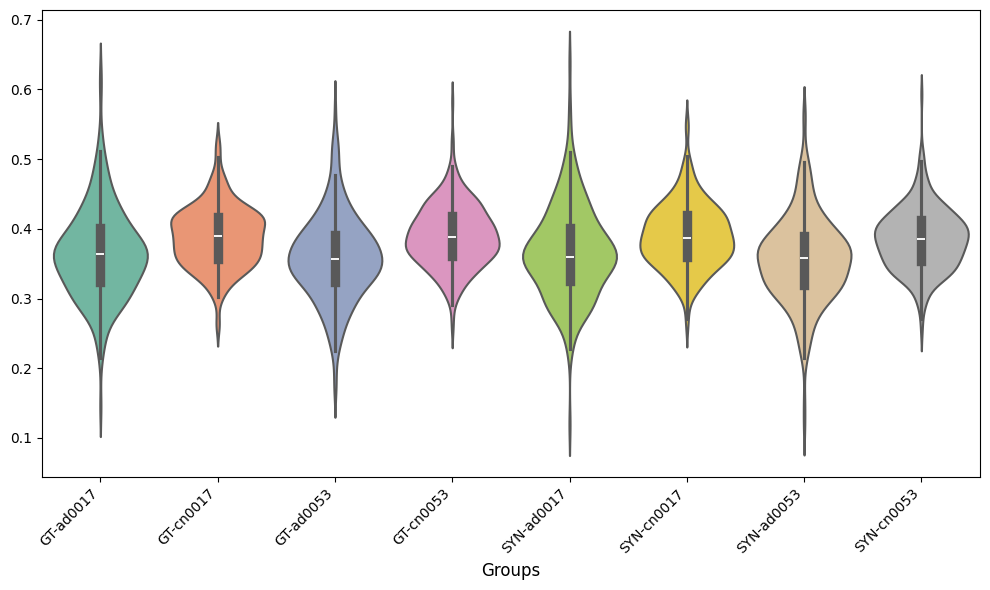

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Load the data
file_path = '/home/liushiyu/liutuo-test/ADNI1+2_baseline/important csv/1753new fakepet_adjusted (2).csv'
data = pd.read_csv(file_path)

# Rename columns to match your desired x-axis labels
data.columns = ["GT-ad0017", "GT-cn0017", "GT-ad0053", "GT-cn0053", "SYN-ad0017", "SYN-cn0017", "SYN-ad0053", "SYN-cn0053"]

# Create the violin plot
plt.figure(figsize=(10, 6))
sns.violinplot(data=data, linewidth=1.5, palette="Set2")

# Modify x-axis labels to make them slanted
plt.xticks(
    rotation=45,  # Rotate x-axis labels
    ha='right',   # Align labels to the right
    fontsize=10   # Set font size
)

# Add axis labels and title
plt.xlabel("Groups", fontsize=12)
# plt.ylabel("Values", fontsize=12)
# plt.title("Violin Plot of Real and Fake PET Values", fontsize=14)

# Display the plot
plt.tight_layout()
plt.show()


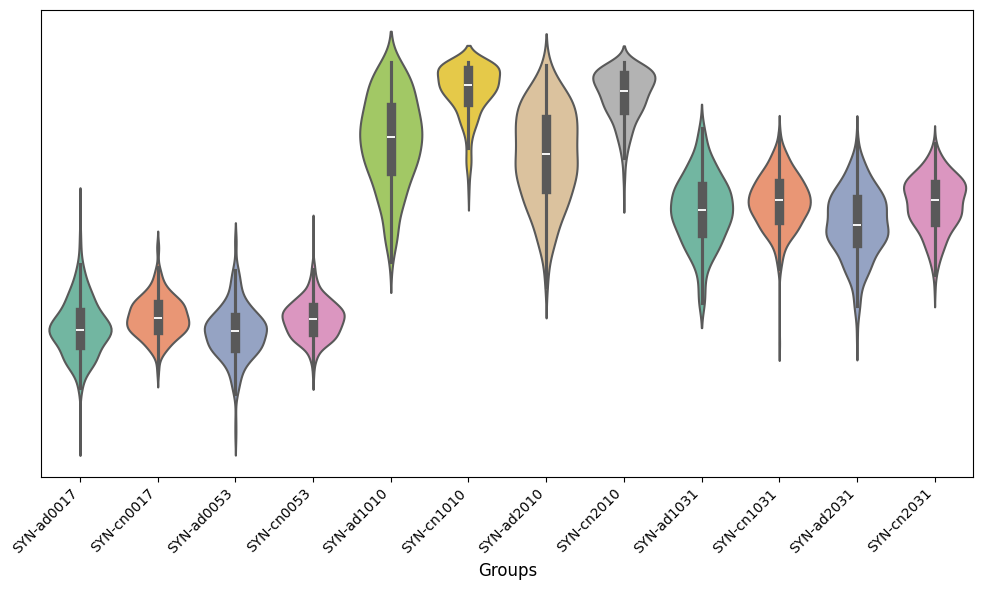

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Load the data
file_path = '/home/liushiyu/liutuo-test/ADNI1+2_baseline/important csv/all (1).csv'
data = pd.read_csv(file_path)

# Rename columns to match your desired x-axis labels
data.columns = ["SYN-ad0017",  "SYN-cn0017", "SYN-ad0053",  "SYN-cn0053",
                "SYN-ad1010",  "SYN-cn1010", "SYN-ad2010",  "SYN-cn2010",
                "SYN-ad1031", "SYN-cn1031", "SYN-ad2031",  "SYN-cn2031"
               ]

# Create the violin plot
plt.figure(figsize=(10, 6))
sns.violinplot(data=data, linewidth=1.5, palette="Set2")

# Modify x-axis labels to make them slanted
plt.xticks(
    rotation=45,  # Rotate x-axis labels
    ha='right',   # Align labels to the right
    fontsize=10   # Set font size
)

# Hide the y-axis
plt.gca().axes.get_yaxis().set_visible(False)

# Add axis labels and title
plt.xlabel("Groups", fontsize=12)

# Display the plot
plt.tight_layout()
plt.show()


In [3]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

# Define the output path
output_path = "/home/liushiyu/liutuo-test/ADNI1+2_baseline/important csv/star1.pdf"

# Ensure the directory exists
os.makedirs(os.path.dirname(output_path), exist_ok=True)

# Plot the violin plot
plt.figure(figsize=(12, 6))
ax = sns.violinplot(data=data, linewidth=1.5, palette="Set2")

# Annotate significance with specific stars for pairs of columns
y_max = data.max().max() + 0.05  # Base height for annotations
h = 0.02  # Vertical spacing for annotations
col = "black"  # Color for annotations

# Define significance levels for specific pairs
significance = {
    (0, 1): "****",    # First and second columns
    (2, 3): "****",   # Third and fourth columns
    (4, 5): "****",    # Fifth and sixth columns
    (6, 7): "****",   # Seventh and eighth columns
    (8, 9): "**", 
    (10, 11):"****", 
 

}

# Add significance annotations
for (x1, x2), stars in significance.items():
    y = y_max + (x1 // 2) * h  # Adjust height based on pair index
    plt.plot([x1, x1, x2, x2], [y, y + h, y + h, y], lw=1.5, color=col)
    plt.text((x1 + x2) * 0.5, y + h, stars, ha="center", va="bottom", color=col, fontsize=12)

# Adjust x-axis labels
plt.xticks(rotation=45, ha='right', fontsize=10)

# Hide y-axis
plt.gca().axes.get_yaxis().set_visible(False)

# Add title
plt.title("AD VS CN ", fontsize=14)

# Save as PDF
plt.tight_layout()
plt.savefig(output_path, format='pdf')
plt.close()

print(f"File saved to: {output_path}")



File saved to: /home/liushiyu/liutuo-test/ADNI1+2_baseline/important csv/star1.png


In [5]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

# Define the output path
output_path = "/home/liushiyu/liutuo-test/ADNI1+2_baseline/important csv/star1.png"

# Ensure the directory exists
os.makedirs(os.path.dirname(output_path), exist_ok=True)

# Plot the violin plot
plt.figure(figsize=(12, 6))
ax = sns.violinplot(data=data, linewidth=1.5, palette="Set2")

# Annotate significance with specific stars for pairs of columns
y_max = data.max().max() + 0.05  # Base height for annotations
h = 0.02  # Vertical spacing for annotations
col = "black"  # Color for annotations

# Define significance levels for specific pairs
significance = {
    (0, 1): "****",    # First and second columns
    (2, 3): "****",   # Third and fourth columns
    (4, 5): "****",    # Fifth and sixth columns
    (6, 7): "****",   # Seventh and eighth columns
    (8, 9): "**", 
    (10, 11):"****", 
}

# Add significance annotations
for (x1, x2), stars in significance.items():
    y = y_max + (x1 // 2) * h  # Adjust height based on pair index
    plt.plot([x1, x1, x2, x2], [y, y + h, y + h, y], lw=1.5, color=col)
    plt.text((x1 + x2) * 0.5, y + h, stars, ha="center", va="bottom", color=col, fontsize=12)

# Adjust x-axis labels
plt.xticks(rotation=45, ha='right', fontsize=10)

# Hide y-axis
plt.gca().axes.get_yaxis().set_visible(False)

# # Add title
# plt.title("AD VS CN ", fontsize=14)

# Save as PNG
plt.tight_layout()
plt.savefig(output_path, format='png')  # Change format to PNG
plt.close()

print(f"File saved to: {output_path}")


File saved to: /home/liushiyu/liutuo-test/ADNI1+2_baseline/important csv/star1.png


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.image as mpimg

# 加载图像
# 替换为实际图像文件路径
gt_cn_17 = mpimg.imread("gt_cn_17.png")  # GT for CN (Region 17)
synthetic_cn_17 = mpimg.imread("synthetic_cn_17.png")
gt_ad_17 = mpimg.imread("gt_ad_17.png")  # GT for AD (Region 17)
synthetic_ad_17 = mpimg.imread("synthetic_ad_17.png")

gt_cn_1010 = mpimg.imread("gt_cn_1010.png")  # GT for CN (Region 1010)
synthetic_cn_1010 = mpimg.imread("synthetic_cn_1010.png")
gt_ad_1010 = mpimg.imread("gt_ad_1010.png")  # GT for AD (Region 1010)
synthetic_ad_1010 = mpimg.imread("synthetic_ad_1010.png")

gt_cn_1031 = mpimg.imread("gt_cn_1031.png")  # GT for CN (Region 1031)
synthetic_cn_1031 = mpimg.imread("synthetic_cn_1031.png")
gt_ad_1031 = mpimg.imread("gt_ad_1031.png")  # GT for AD (Region 1031)
synthetic_ad_1031 = mpimg.imread("synthetic_ad_1031.png")

# 创建一个 3x4 网格的图表
fig = plt.figure(figsize=(12, 9))
gs = gridspec.GridSpec(3, 4, figure=fig, wspace=0.3, hspace=0.4)

# 第一行: 区域 17
ax1 = fig.add_subplot(gs[0, 0])
ax1.imshow(gt_cn_17, cmap='gray')
ax1.set_title("GT CN (17)")
ax1.axis('off')

ax2 = fig.add_subplot(gs[0, 1])
ax2.imshow(synthetic_cn_17, cmap='gray')
ax2.set_title("Synthetic CN (17)")
ax2.axis('off')

ax3 = fig.add_subplot(gs[0, 2])
ax3.imshow(gt_ad_17, cmap='gray')
ax3.set_title("GT AD (17)")
ax3.axis('off')

ax4 = fig.add_subplot(gs[0, 3])
ax4.imshow(synthetic_ad_17, cmap='gray')
ax4.set_title("Synthetic AD (17)")
ax4.axis('off')

# 第二行: 区域 1010
ax5 = fig.add_subplot(gs[1, 0])
ax5.imshow(gt_cn_1010, cmap='gray')
ax5.set_title("GT CN (1010)")
ax5.axis('off')

ax6 = fig.add_subplot(gs[1, 1])
ax6.imshow(synthetic_cn_1010, cmap='gray')
ax6.set_title("Synthetic CN (1010)")
ax6.axis('off')

ax7 = fig.add_subplot(gs[1, 2])
ax7.imshow(gt_ad_1010, cmap='gray')
ax7.set_title("GT AD (1010)")
ax7.axis('off')

ax8 = fig.add_subplot(gs[1, 3])
ax8.imshow(synthetic_ad_1010, cmap='gray')
ax8.set_title("Synthetic AD (1010)")
ax8.axis('off')

# 第三行: 区域 1031
ax9 = fig.add_subplot(gs[2, 0])
ax9.imshow(gt_cn_1031, cmap='gray')
ax9.set_title("GT CN (1031)")
ax9.axis('off')

ax10 = fig.add_subplot(gs[2, 1])
ax10.imshow(synthetic_cn_1031, cmap='gray')
ax10.set_title("Synthetic CN (1031)")
ax10.axis('off')

ax11 = fig.add_subplot(gs[2, 2])
ax11.imshow(gt_ad_1031, cmap='gray')
ax11.set_title("GT AD (1031)")
ax11.axis('off')

ax12 = fig.add_subplot(gs[2, 3])
ax12.imshow(synthetic_ad_1031, cmap='gray')
ax12.set_title("Synthetic AD (1031)")
ax12.axis('off')

# 添加整体标题
fig.suptitle("Comparison of GT and Synthetic PET Images Across Brain Regions", fontsize=16)

# 保存图像或展示
plt.tight_layout()
plt.savefig("comparison_plot.pdf", format='pdf')
plt.show()


In [2]:
import os
import numpy as np
import nibabel as nib
import pandas as pd

# 定义路径
mri_seg_dir = "/home/ssddata/liutuo/liutuo_data/data_augmentation_mri_fenge"
real_av45_dir = "/home/ssddata/liutuo/liutuo_data/data_augmentation_av45"
syn_av45_dir = "/home/ssddata/liutuo/liutuo_data/data_augmentation_av45_generated"
output_dir = "/home/ssddata/liutuo/liutuo_data/statistics_of_regions_av45_new"

# 创建输出目录（如果不存在）
os.makedirs(output_dir, exist_ok=True)

# 获取文件列表
def get_file_list(dir_path, ext=".nii.gz"):
    return [file for file in os.listdir(dir_path) if file.endswith(ext)]

# 获取匹配的文件名
def get_matched_files(mri_seg_dir, real_av45_dir, syn_av45_dir):
    mri_files = get_file_list(mri_seg_dir)
    real_av45_files = get_file_list(real_av45_dir)
    syn_av45_files = get_file_list(syn_av45_dir)

    # 提取文件名前缀
    mri_names = {os.path.splitext(os.path.splitext(file)[0])[0].replace("fenge", "") for file in mri_files}
    real_av45_names = {os.path.splitext(os.path.splitext(file)[0])[0] for file in real_av45_files}
    syn_av45_names = {os.path.splitext(os.path.splitext(file)[0])[0] for file in syn_av45_files}

    # 找出共同的文件名
    common_names = sorted(mri_names & real_av45_names & syn_av45_names)
    return common_names

# 加载 NIfTI 文件
def load_nifti(file_path):
    return nib.load(file_path).get_fdata()

# 初始化存储结果的字典
def initialize_results_dict(unique_labels):
    results = {}
    for label in unique_labels:
        results[label] = {"subject": [], "real_av45_mean": [], "syn_av45_mean": []}
    return results

# 主逻辑：处理所有匹配的数据
common_names = get_matched_files(mri_seg_dir, real_av45_dir, syn_av45_dir)

if not common_names:
    print("No matching files found!")
else:
    # 初始化结果字典
    first_name = common_names[0]
    mri_seg_path = os.path.join(mri_seg_dir, f"{first_name}fenge.nii.gz")
    mri_seg = load_nifti(mri_seg_path)
    unique_labels = np.unique(mri_seg)
    unique_labels = unique_labels[unique_labels > 0]  # 去掉背景区域 (label=0)
    results = initialize_results_dict(unique_labels)

    # 遍历所有匹配的数据
    for name in common_names:
        print(f"\nProcessing matched data: {name}")

        # 加载 MRI 分割、真实 AV45 和合成 AV45 图像
        mri_seg_path = os.path.join(mri_seg_dir, f"{name}fenge.nii.gz")
        real_av45_path = os.path.join(real_av45_dir, f"{name}.nii.gz")
        syn_av45_path = os.path.join(syn_av45_dir, f"{name}.nii.gz")

        mri_seg = load_nifti(mri_seg_path)  # 脑区分割掩码
        real_av45 = load_nifti(real_av45_path)  # 真实 AV45 图像
        syn_av45 = load_nifti(syn_av45_path)  # 合成 AV45 图像

        # 遍历每个脑区
        for label in unique_labels:
            mask = mri_seg == label  # 提取当前脑区的掩码

            # 计算当前脑区的真实 AV45 和合成 AV45 的均值
            real_mean = np.mean(real_av45[mask])
            syn_mean = np.mean(syn_av45[mask])

            # 存储结果
            results[label]["subject"].append(name)
            results[label]["real_av45_mean"].append(real_mean)
            results[label]["syn_av45_mean"].append(syn_mean)

    # 将结果保存为 CSV 文件
    for label in unique_labels:
        csv_data = {
            "subject": results[label]["subject"],
            "real_av45_mean": results[label]["real_av45_mean"],
            "syn_av45_mean": results[label]["syn_av45_mean"]
        }
        df = pd.DataFrame(csv_data)
        csv_path = os.path.join(output_dir, f"region_{label}.csv")
        df.to_csv(csv_path, index=False)
        print(f"Saved results for brain region {label} to {csv_path}")


Processing matched data: 002_S_0295

Processing matched data: 002_S_0413

Processing matched data: 002_S_0685

Processing matched data: 002_S_0729

Processing matched data: 002_S_1155

Processing matched data: 002_S_1261

Processing matched data: 002_S_1268

Processing matched data: 002_S_1280

Processing matched data: 002_S_2010

Processing matched data: 002_S_2043

Processing matched data: 002_S_2073

Processing matched data: 002_S_4171

Processing matched data: 002_S_4213

Processing matched data: 002_S_4219

Processing matched data: 002_S_4225

Processing matched data: 002_S_4229

Processing matched data: 002_S_4237

Processing matched data: 002_S_4251

Processing matched data: 002_S_4262

Processing matched data: 002_S_4270

Processing matched data: 002_S_4447

Processing matched data: 002_S_4473

Processing matched data: 002_S_4521

Processing matched data: 002_S_4654

Processing matched data: 002_S_4746

Processing matched data: 002_S_4799

Processing matched data: 002_S_5018



In [1]:
import os
import numpy as np
import nibabel as nib
import pandas as pd

# 定义路径
mri_seg_dir = "/home/ssddata/liutuo/liutuo_data/data_augmentation_mri_fenge"
real_fdg_dir = "/home/ssddata/liutuo/liutuo_data/data_augmentation_fdg"
syn_fdg_dir = "/home/ssddata/liutuo/liutuo_data/data_augmentation_fdg_generated"
output_dir = "/home/ssddata/liutuo/liutuo_data/statistics_of_regions_fdg_new"

# 创建输出目录（如果不存在）
os.makedirs(output_dir, exist_ok=True)

# 获取文件列表
def get_file_list(dir_path, ext=".nii.gz"):
    return [file for file in os.listdir(dir_path) if file.endswith(ext)]

# 获取匹配的文件名
def get_matched_files(mri_seg_dir, real_fdg_dir, syn_fdg_dir):
    mri_files = get_file_list(mri_seg_dir)
    real_fdg_files = get_file_list(real_fdg_dir)
    syn_fdg_files = get_file_list(syn_fdg_dir)

    # 提取文件名前缀
    mri_names = {os.path.splitext(os.path.splitext(file)[0])[0].replace("fenge", "") for file in mri_files}
    real_fdg_names = {os.path.splitext(os.path.splitext(file)[0])[0] for file in real_fdg_files}
    syn_fdg_names = {os.path.splitext(os.path.splitext(file)[0])[0] for file in syn_fdg_files}

    # 找出共同的文件名
    common_names = sorted(mri_names & real_fdg_names & syn_fdg_names)
    return common_names

# 加载 NIfTI 文件
def load_nifti(file_path):
    return nib.load(file_path).get_fdata()

# 初始化存储结果的字典
def initialize_results_dict(unique_labels):
    results = {}
    for label in unique_labels:
        results[label] = {"subject": [], "real_fdg_mean": [], "syn_fdg_mean": []}
    return results

# 主逻辑：处理所有匹配的数据
common_names = get_matched_files(mri_seg_dir, real_fdg_dir, syn_fdg_dir)

if not common_names:
    print("No matching files found!")
else:
    # 初始化结果字典
    first_name = common_names[0]
    mri_seg_path = os.path.join(mri_seg_dir, f"{first_name}fenge.nii.gz")
    mri_seg = load_nifti(mri_seg_path)
    unique_labels = np.unique(mri_seg)
    unique_labels = unique_labels[unique_labels > 0]  # 去掉背景区域 (label=0)
    results = initialize_results_dict(unique_labels)

    # 遍历所有匹配的数据
    for name in common_names:
        print(f"\nProcessing matched data: {name}")

        # 加载 MRI 分割、真实 AV45 和合成 AV45 图像
        mri_seg_path = os.path.join(mri_seg_dir, f"{name}fenge.nii.gz")
        real_fdg_path = os.path.join(real_fdg_dir, f"{name}.nii.gz")
        syn_fdg_path = os.path.join(syn_fdg_dir, f"{name}.nii.gz")

        mri_seg = load_nifti(mri_seg_path)  # 脑区分割掩码
        real_fdg = load_nifti(real_fdg_path)  # 真实 AV45 图像
        syn_fdg = load_nifti(syn_fdg_path)  # 合成 AV45 图像

        # 遍历每个脑区
        for label in unique_labels:
            mask = mri_seg == label  # 提取当前脑区的掩码

            # 计算当前脑区的真实 AV45 和合成 AV45 的均值
            real_mean = np.mean(real_fdg[mask])
            syn_mean = np.mean(syn_fdg[mask])

            # 存储结果
            results[label]["subject"].append(name)
            results[label]["real_fdg_mean"].append(real_mean)
            results[label]["syn_fdg_mean"].append(syn_mean)

    # 将结果保存为 CSV 文件
    for label in unique_labels:
        csv_data = {
            "subject": results[label]["subject"],
            "real_fdg_mean": results[label]["real_fdg_mean"],
            "syn_fdg_mean": results[label]["syn_fdg_mean"]
        }
        df = pd.DataFrame(csv_data)
        csv_path = os.path.join(output_dir, f"region_{label}.csv")
        df.to_csv(csv_path, index=False)
        print(f"Saved results for brain region {label} to {csv_path}")


Processing matched data: 002_S_0295

Processing matched data: 002_S_0413

Processing matched data: 002_S_0685

Processing matched data: 002_S_0729

Processing matched data: 002_S_1155

Processing matched data: 002_S_1261

Processing matched data: 002_S_1268

Processing matched data: 002_S_1280

Processing matched data: 002_S_2010

Processing matched data: 002_S_2043

Processing matched data: 002_S_2073

Processing matched data: 002_S_4171

Processing matched data: 002_S_4213

Processing matched data: 002_S_4219

Processing matched data: 002_S_4225

Processing matched data: 002_S_4229

Processing matched data: 002_S_4237

Processing matched data: 002_S_4251

Processing matched data: 002_S_4262

Processing matched data: 002_S_4270

Processing matched data: 002_S_4447

Processing matched data: 002_S_4473

Processing matched data: 002_S_4521

Processing matched data: 002_S_4654

Processing matched data: 002_S_4746

Processing matched data: 002_S_4799

Processing matched data: 002_S_5018



/home/pnxc/Anaconda3/envs/xiaochou/lib/python3.10/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/pnxc/Anaconda3/envs/xiaochou/lib/python3.10/site-packages/numpy/_core/_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)



Processing matched data: 010_S_0788

Processing matched data: 010_S_0904

Processing matched data: 010_S_4345

Processing matched data: 010_S_4442

Processing matched data: 010_S_6748

Processing matched data: 011_S_0003

Processing matched data: 011_S_0005

Processing matched data: 011_S_0008

Processing matched data: 011_S_0010

Processing matched data: 011_S_0016

Processing matched data: 011_S_0021

Processing matched data: 011_S_0023

Processing matched data: 011_S_0053

Processing matched data: 011_S_0183

Processing matched data: 011_S_0326

Processing matched data: 011_S_0362

Processing matched data: 011_S_0861

Processing matched data: 011_S_1282

Processing matched data: 011_S_2274

Processing matched data: 011_S_4075

Processing matched data: 011_S_4105

Processing matched data: 011_S_4120

Processing matched data: 011_S_4222

Processing matched data: 011_S_4235

Processing matched data: 011_S_4278

Processing matched data: 011_S_4366

Processing matched data: 011_S_4547



Region 2.0:
  T-statistic: 0.2573, P-value: 0.7970
  No significant difference.
Region 4.0:
  T-statistic: -1.5389, P-value: 0.1239
  No significant difference.
Region 5.0:
  T-statistic: -1.5840, P-value: 0.1133
  No significant difference.
Region 7.0:
  T-statistic: nan, P-value: nan
  No significant difference.
Region 8.0:
  T-statistic: -2.8052, P-value: 0.0051
  No significant difference.
Region 10.0:
  T-statistic: -5.0624, P-value: 0.0000
  Significant difference detected!
Region 11.0:
  T-statistic: -1.7831, P-value: 0.0747
  No significant difference.
Region 12.0:
  T-statistic: -2.9370, P-value: 0.0033
  Significant difference detected!
Region 13.0:
  T-statistic: -5.0483, P-value: 0.0000
  Significant difference detected!
Region 14.0:
  T-statistic: -2.4920, P-value: 0.0128
  No significant difference.
Region 15.0:
  T-statistic: -3.2114, P-value: 0.0013
  Significant difference detected!
Region 16.0:
  T-statistic: -2.3614, P-value: 0.0183
  No significant difference.
Saved

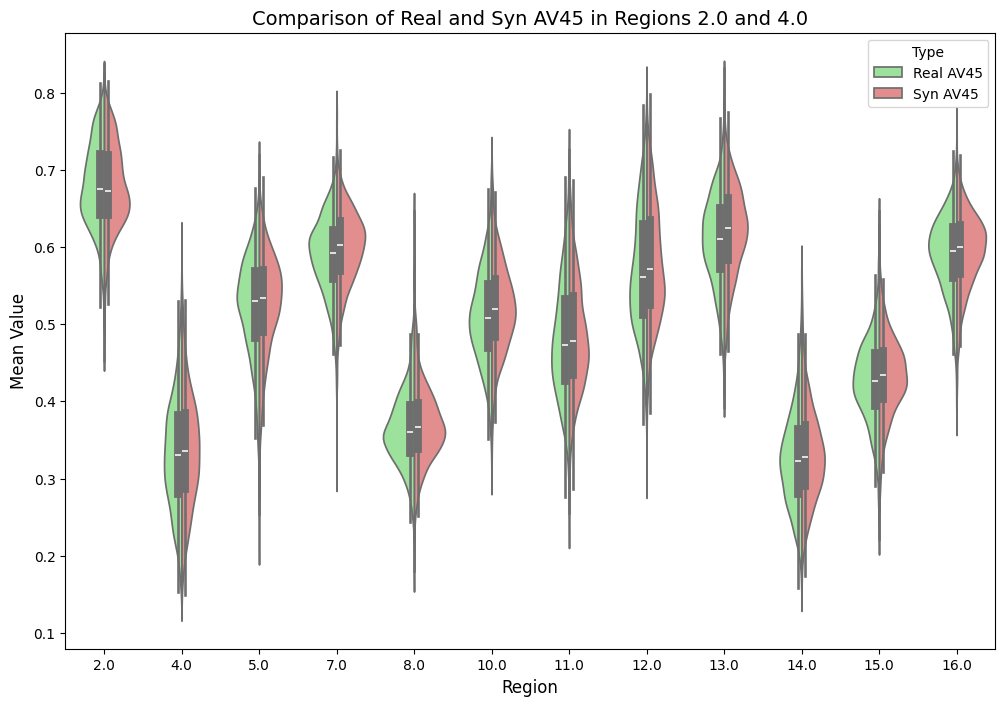

In [14]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind

# 定义路径
output_dir = "/home/ssddata/liutuo/liutuo_data/statistics_of_regions"

# 加载 CSV 文件
def load_csv(file_path):
    return pd.read_csv(file_path)

# 统计检验和绘图
def analyze_and_plot(regions_to_analyze):
    # 创建一个 DataFrame 存储所有数据
    all_data = []

    for region in regions_to_analyze:
        csv_path = os.path.join(output_dir, f"region_{region}.csv")
        if not os.path.exists(csv_path):
            print(f"File not found: {csv_path}")
            continue

        csv_data = load_csv(csv_path)
        real_av45 = csv_data["real_av45_mean"].values
        syn_av45 = csv_data["syn_av45_mean"].values

        # 独立样本 t 检验
        t_stat, p_value = ttest_ind(real_av45, syn_av45)
        print(f"Region {region}:")
        print(f"  T-statistic: {t_stat:.4f}, P-value: {p_value:.4f}")
        if p_value < 0.005:
            print("  Significant difference detected!")
        else:
            print("  No significant difference.")

        # 合并数据为长格式
        data = pd.DataFrame({
            "Real AV45": real_av45,
            "Syn AV45": syn_av45
        }).melt(var_name="Type", value_name="Mean Value")

        # 添加区域标签
        data["Region"] = region

        # 将数据追加到总数据集
        all_data.append(data)

    # 合并所有数据
    combined_data = pd.concat(all_data, ignore_index=True)

    # 绘制小提琴图
    plt.figure(figsize=(12, 8))
    sns.violinplot(data=combined_data, x="Region", y="Mean Value", hue="Type", inner="box", split=True, palette=["lightgreen", "lightcoral"])
    plt.title("Comparison of Real and Syn AV45 in Regions 2.0 and 4.0", fontsize=14)
    plt.ylabel("Mean Value", fontsize=12)
    plt.xlabel("Region", fontsize=12)
    plt.legend(title="Type", loc="upper right")

    # 保存图像
    plot_path = os.path.join(output_dir, "regions_2.0_4.0_comparison_violin.png")
    plt.savefig(plot_path)
    print(f"Saved plot to {plot_path}")

    # 显示图像
    plt.show()

# 主逻辑
regions_to_analyze = ["2.0", "4.0", "5.0", "7.0", "8.0", "10.0", "11.0", "12.0", "13.0", "14.0", "15.0", "16.0"]
analyze_and_plot(regions_to_analyze)

Region 2.0:
  T-statistic: 0.1590, P-value: 0.8736
  No significant difference.
Region 4.0:
  T-statistic: 0.0896, P-value: 0.9286
  No significant difference.
Region 5.0:
  T-statistic: 0.1349, P-value: 0.8927
  No significant difference.
Region 10.0:
  T-statistic: 0.1382, P-value: 0.8901
  No significant difference.
Region 11.0:
  T-statistic: -0.2649, P-value: 0.7911
  No significant difference.
Region 12.0:
  T-statistic: -0.1337, P-value: 0.8936
  No significant difference.
Region 13.0:
  T-statistic: -0.0112, P-value: 0.9911
  No significant difference.
Region 14.0:
  T-statistic: -0.2890, P-value: 0.7726
  No significant difference.
Region 15.0:
  T-statistic: -0.0592, P-value: 0.9528
  No significant difference.
Region 16.0:
  T-statistic: 0.4343, P-value: 0.6641
  No significant difference.
Region 17.0:
  T-statistic: -0.3557, P-value: 0.7221
  No significant difference.
Region 18.0:
  T-statistic: nan, P-value: nan
  No significant difference.
Region 24.0:
  T-statistic: 0.5

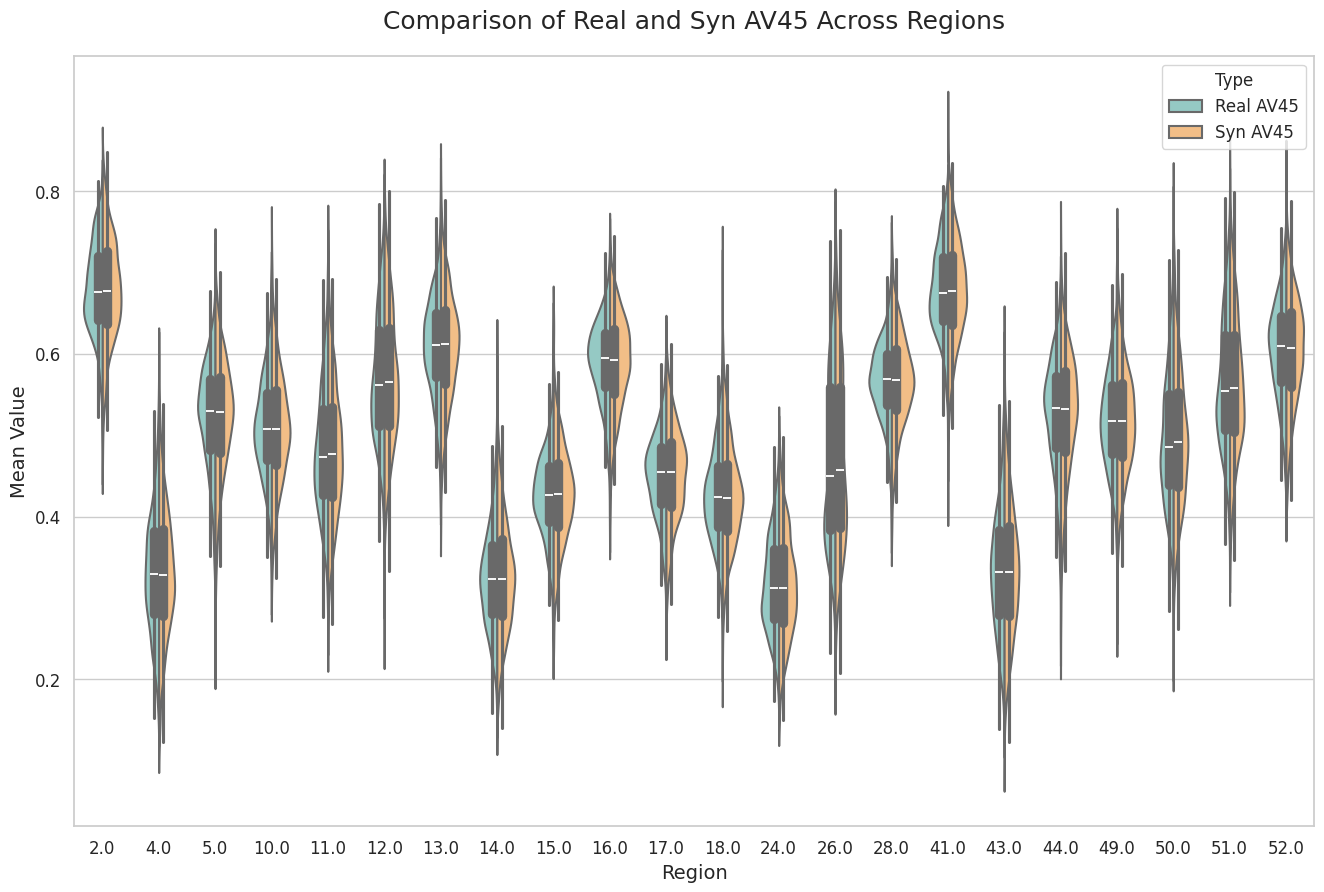

In [6]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind

# 定义路径
output_dir = "/home/ssddata/liutuo/liutuo_data/statistics_of_regions_av45"

# 加载 CSV 文件
def load_csv(file_path):
    return pd.read_csv(file_path)

# 统计检验和绘图
def analyze_and_plot(regions_to_analyze):
    # 创建一个 DataFrame 存储所有数据
    all_data = []

    # 用于保存显著性信息
    significance_info = {}

    for region in regions_to_analyze:
        csv_path = os.path.join(output_dir, f"region_{region}.csv")
        if not os.path.exists(csv_path):
            print(f"File not found: {csv_path}")
            continue

        csv_data = load_csv(csv_path)
        real_av45 = csv_data["real_av45_mean"].values
        syn_av45 = csv_data["syn_av45_mean"].values

        # 独立样本 t 检验
        t_stat, p_value = ttest_ind(real_av45, syn_av45)
        print(f"Region {region}:")
        print(f"  T-statistic: {t_stat:.4f}, P-value: {p_value:.4f}")
        if p_value < 0.05:
            print("  Significant difference detected!")
            significance_info[region] = "Significant"
        else:
            print("  No significant difference.")
            significance_info[region] = "Not Significant"

        # 合并数据为长格式
        data = pd.DataFrame({
            "Real AV45": real_av45,
            "Syn AV45": syn_av45
        }).melt(var_name="Type", value_name="Mean Value")

        # 添加区域标签
        data["Region"] = region

        # 将数据追加到总数据集
        all_data.append(data)

    # 合并所有数据
    combined_data = pd.concat(all_data, ignore_index=True)

    # 设置 Seaborn 主题和颜色
    sns.set_theme(style="whitegrid")
    palette = {"Real AV45": "#8ECFC9", "Syn AV45": "#FFBE7A"}  # 更柔和的颜色

    # 绘制小提琴图 + 箱线图
    plt.figure(figsize=(16, 10))
    ax = sns.violinplot(
        data=combined_data,
        x="Region",
        y="Mean Value",
        hue="Type",
        inner="box",
        split=True,
        palette=palette,
        linewidth=1.5,
        saturation=0.8
    )

    # 添加显著性标注
    y_max = combined_data["Mean Value"].max() * 1.1  # 动态计算 y 轴最大值
    for i, region in enumerate(regions_to_analyze):
        if region in significance_info and significance_info[region] == "Significant":
            plt.text(i, y_max, "*", ha="center", fontsize=16, color="red", fontweight="bold")

    # 图形细节优化
    plt.title("Comparison of Real and Syn AV45 Across Regions", fontsize=18, pad=20)
    plt.ylabel("Mean Value", fontsize=14)
    plt.xlabel("Region", fontsize=14)
    plt.xticks(fontsize=12)
    plt.yticks(fontsize=12)
    plt.legend(title="Type", title_fontsize=12, fontsize=12, loc="upper right", frameon=True)

    # 保存图像
    plot_path = os.path.join(output_dir, "regions_comparison_violin.png")
    plt.savefig(plot_path, dpi=300, bbox_inches="tight")
    print(f"Saved plot to {plot_path}")

    # 显示图像
    plt.show()

# 主逻辑
regions_to_analyze = [2.0, 4.0, 5.0, 10.0, 11.0, 12.0, 13.0, 14.0, 15.0, 16.0, 17.0, 18.0, 24.0, 26.0, 28.0, 41.0, 43.0, 44.0, 49.0, 50.0, 51.0, 52.0]
analyze_and_plot(regions_to_analyze)

Analyzing the first 10 CSV files: ['region_ctx-rh-cuneus.csv', 'region_ctx-rh-rostralmiddlefrontal.csv', 'region_ctx-rh-fusiform.csv', 'region_ctx-rh-insula.csv', 'region_ctx-lh-lateralorbitofrontal.csv', 'region_Brain-Stem.csv', 'region_ctx-rh-posteriorcingulate.csv', 'region_Right-Pallidum.csv', 'region_ctx-rh-lateralorbitofrontal.csv', 'region_Right-Cerebral-White-Matter.csv']
Region ctx-rh-cuneus:
  T-statistic: 0.1350, P-value: 0.8926
  No significant difference.
Region ctx-rh-rostralmiddlefrontal:
  T-statistic: 0.1603, P-value: 0.8726
  No significant difference.
Region ctx-rh-fusiform:
  T-statistic: -0.0455, P-value: 0.9637
  No significant difference.
Region ctx-rh-insula:
  T-statistic: -0.3410, P-value: 0.7331
  No significant difference.
Region ctx-lh-lateralorbitofrontal:
  T-statistic: -0.1292, P-value: 0.8972
  No significant difference.
Region Brain-Stem:
  T-statistic: 0.4343, P-value: 0.6641
  No significant difference.
Region ctx-rh-posteriorcingulate:
  T-statistic

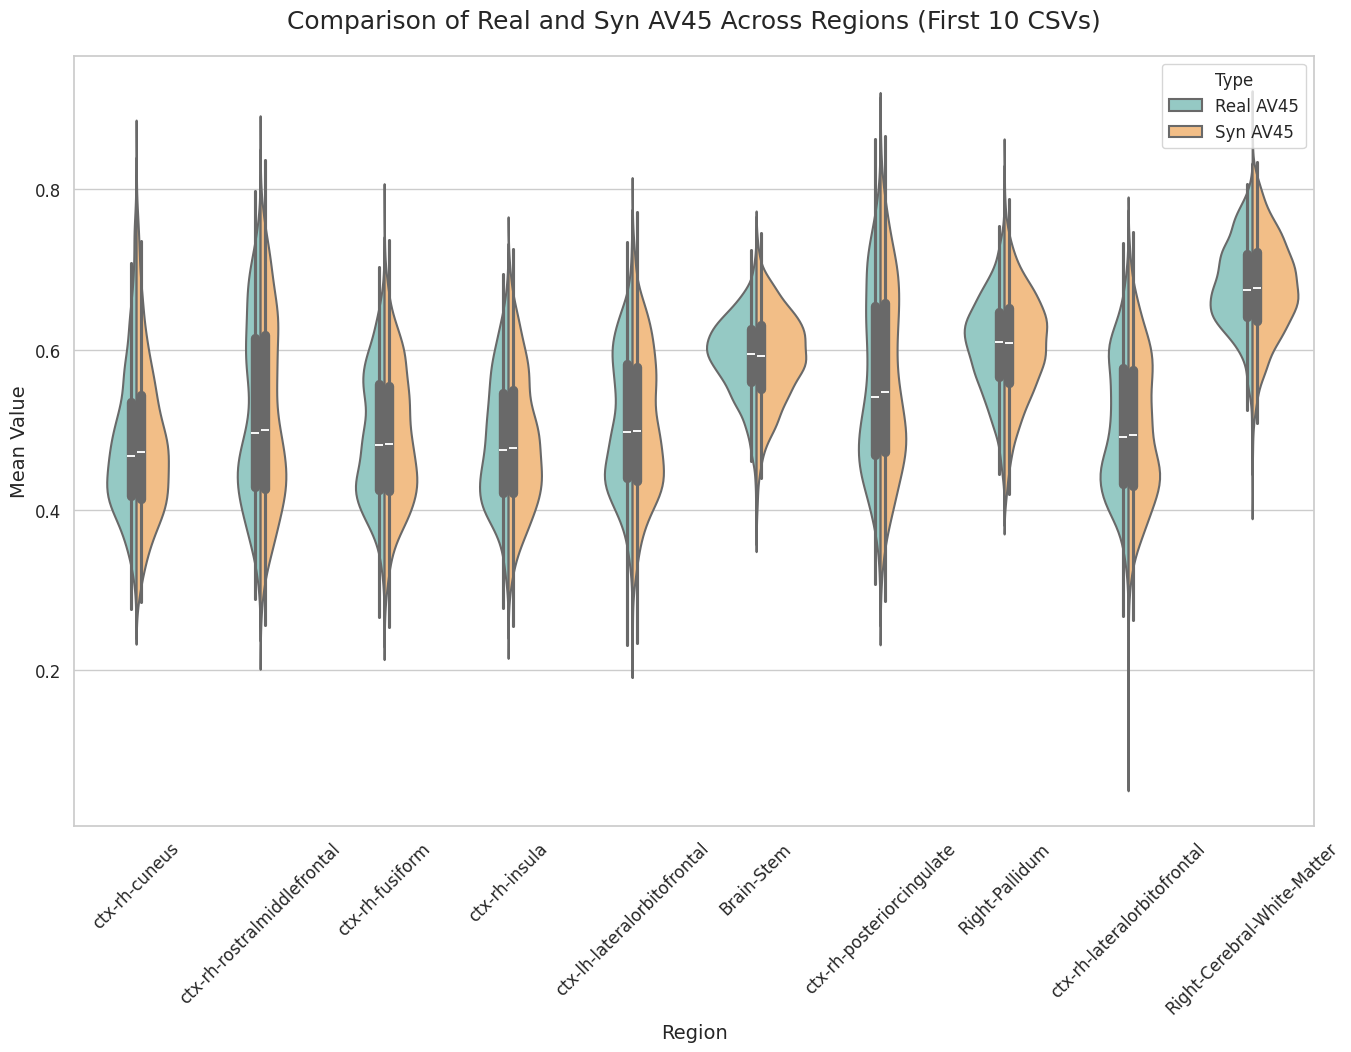

In [10]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind

# 定义路径
output_dir = "/home/ssddata/liutuo/liutuo_data/statistics_of_regions_av45"

# 加载 CSV 文件
def load_csv(file_path):
    return pd.read_csv(file_path)

# 统计检验和绘图
def analyze_and_plot():
    # 获取目录中的所有 CSV 文件
    csv_files = [f for f in os.listdir(output_dir) if f.endswith(".csv")]
    
    # 如果没有 CSV 文件，直接退出
    if not csv_files:
        print("No CSV files found in the directory.")
        return

    # 只取前 10 个 CSV 文件
    csv_files = csv_files[:10]
    print(f"Analyzing the first 10 CSV files: {csv_files}")

    # 创建一个 DataFrame 存储所有数据
    all_data = []

    # 用于保存显著性信息
    significance_info = {}

    for csv_file in csv_files:
        csv_path = os.path.join(output_dir, csv_file)
        if not os.path.exists(csv_path):
            print(f"File not found: {csv_path}")
            continue

        # 提取区域名称（去掉 "region_" 和 ".csv"）
        region = os.path.splitext(csv_file)[0].replace("region_", "")

        csv_data = load_csv(csv_path)
        real_av45 = csv_data["real_av45_mean"].values
        syn_av45 = csv_data["syn_av45_mean"].values

        # 独立样本 t 检验
        t_stat, p_value = ttest_ind(real_av45, syn_av45)
        print(f"Region {region}:")
        print(f"  T-statistic: {t_stat:.4f}, P-value: {p_value:.4f}")
        if p_value < 0.05:
            print("  Significant difference detected!")
            significance_info[region] = "Significant"
        else:
            print("  No significant difference.")
            significance_info[region] = "Not Significant"

        # 合并数据为长格式
        data = pd.DataFrame({
            "Real AV45": real_av45,
            "Syn AV45": syn_av45
        }).melt(var_name="Type", value_name="Mean Value")

        # 添加区域标签
        data["Region"] = region

        # 将数据追加到总数据集
        all_data.append(data)

    # 合并所有数据
    combined_data = pd.concat(all_data, ignore_index=True)

    # 设置 Seaborn 主题和颜色
    sns.set_theme(style="whitegrid")
    palette = {"Real AV45": "#8ECFC9", "Syn AV45": "#FFBE7A"}  # 更柔和的颜色

    # 绘制小提琴图 + 箱线图
    plt.figure(figsize=(16, 10))
    ax = sns.violinplot(
        data=combined_data,
        x="Region",
        y="Mean Value",
        hue="Type",
        inner="box",
        split=True,
        palette=palette,
        linewidth=1.5,
        saturation=0.8
    )

    # 添加显著性标注
    y_max = combined_data["Mean Value"].max() * 1.1  # 动态计算 y 轴最大值
    for i, region in enumerate(significance_info.keys()):
        if significance_info[region] == "Significant":
            plt.text(i, y_max, "*", ha="center", fontsize=16, color="red", fontweight="bold")

    # 图形细节优化
    plt.title("Comparison of Real and Syn AV45 Across Regions (First 10 CSVs)", fontsize=18, pad=20)
    plt.ylabel("Mean Value", fontsize=14)
    plt.xlabel("Region", fontsize=14)
    plt.xticks(fontsize=12, rotation=45)  # 旋转 x 轴标签以便更好显示
    plt.yticks(fontsize=12)
    plt.legend(title="Type", title_fontsize=12, fontsize=12, loc="upper right", frameon=True)

    # 保存图像
    plot_path = os.path.join(output_dir, "regions_comparison_violin_first_10.png")
    plt.savefig(plot_path, dpi=300, bbox_inches="tight")
    print(f"Saved plot to {plot_path}")

    # 显示图像
    plt.show()

# 主逻辑
analyze_and_plot()

Analyzing the first 12 CSV files: ['region_ctx-rh-cuneus.csv', 'region_ctx-rh-rostralmiddlefrontal.csv', 'region_ctx-rh-fusiform.csv', 'region_ctx-rh-insula.csv', 'region_ctx-lh-lateralorbitofrontal.csv', 'region_Brain-Stem.csv', 'region_ctx-rh-posteriorcingulate.csv', 'region_Right-Pallidum.csv', 'region_ctx-rh-lateralorbitofrontal.csv', 'region_Right-Cerebral-White-Matter.csv', 'region_ctx-rh-superiorfrontal.csv', 'region_ctx-lh-rostralmiddlefrontal.csv']
Region ctx-rh-cuneus:
  T-statistic: 0.1350, P-value: 0.8926
  No significant difference.
Region ctx-rh-rostralmiddlefrontal:
  T-statistic: 0.1603, P-value: 0.8726
  No significant difference.
Region ctx-rh-fusiform:
  T-statistic: -0.0455, P-value: 0.9637
  No significant difference.
Region ctx-rh-insula:
  T-statistic: -0.3410, P-value: 0.7331
  No significant difference.
Region ctx-lh-lateralorbitofrontal:
  T-statistic: -0.1292, P-value: 0.8972
  No significant difference.
Region Brain-Stem:
  T-statistic: 0.4343, P-value: 0.66

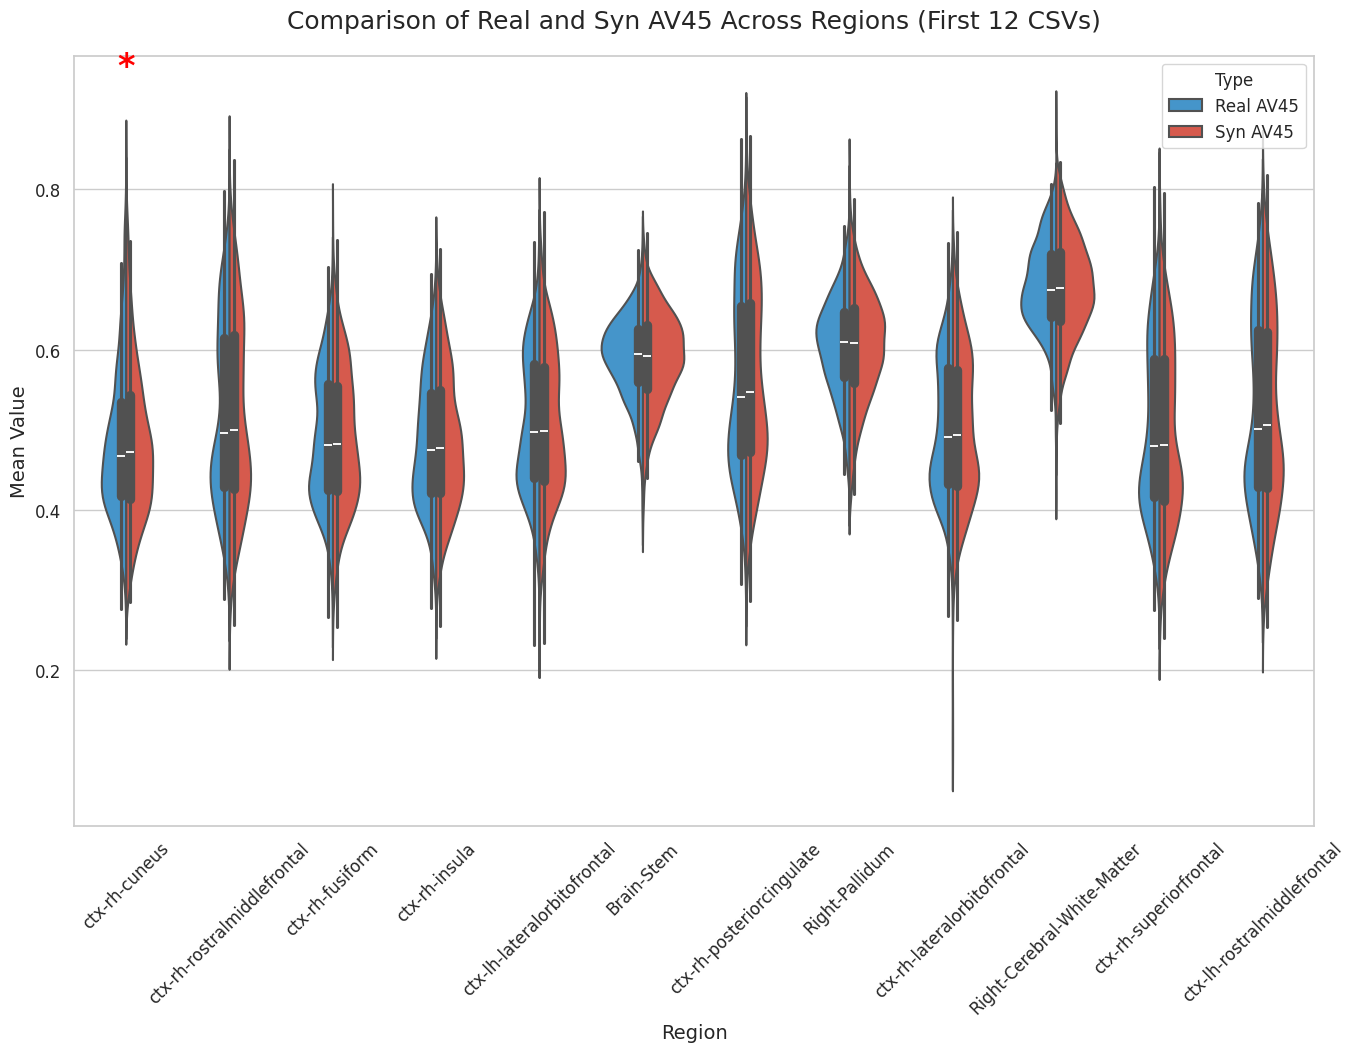

In [20]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind

# 定义路径
output_dir = "/home/ssddata/liutuo/liutuo_data/statistics_of_regions_av45"

# 加载 CSV 文件
def load_csv(file_path):
    return pd.read_csv(file_path)

# 统计检验和绘图
def analyze_and_plot():
    # 获取目录中的所有 CSV 文件
    csv_files = [f for f in os.listdir(output_dir) if f.endswith(".csv")]
    
    # 如果没有 CSV 文件，直接退出
    if not csv_files:
        print("No CSV files found in the directory.")
        return

    # 只取前 12 个 CSV 文件
    csv_files = csv_files[:12]
    print(f"Analyzing the first 12 CSV files: {csv_files}")

    # 创建一个 DataFrame 存储所有数据
    all_data = []

    # 用于保存显著性信息
    significance_info = {}

    for csv_file in csv_files:
        csv_path = os.path.join(output_dir, csv_file)
        if not os.path.exists(csv_path):
            print(f"File not found: {csv_path}")
            continue

        # 提取区域名称（去掉 "region_" 和 ".csv"）
        region = os.path.splitext(csv_file)[0].replace("region_", "")

        csv_data = load_csv(csv_path)
        real_av45 = csv_data["real_av45_mean"].values
        syn_av45 = csv_data["syn_av45_mean"].values

        # 独立样本 t 检验
        t_stat, p_value = ttest_ind(real_av45, syn_av45)
        print(f"Region {region}:")
        print(f"  T-statistic: {t_stat:.4f}, P-value: {p_value:.4f}")
        if p_value < 0.05:
            print("  Significant difference detected!")
            significance_info[region] = "Significant"
        else:
            print("  No significant difference.")
            significance_info[region] = "Not Significant"

        # 合并数据为长格式
        data = pd.DataFrame({
            "Real AV45": real_av45,
            "Syn AV45": syn_av45
        }).melt(var_name="Type", value_name="Mean Value")

        # 添加区域标签
        data["Region"] = region

        # 将数据追加到总数据集
        all_data.append(data)

    # 合并所有数据
    combined_data = pd.concat(all_data, ignore_index=True)

    # 设置 Seaborn 主题和颜色
    sns.set_theme(style="whitegrid")
    # 自定义颜色方案
    palette = {"Real AV45": "#3498DB", "Syn AV45": "#E74C3C"}  # 蓝色和红色

    # 绘制小提琴图 + 箱线图
    plt.figure(figsize=(16, 10))
    ax = sns.violinplot(
        data=combined_data,
        x="Region",
        y="Mean Value",
        hue="Type",
        inner="box",
        split=True,
        palette=palette,
        linewidth=1.5,
        saturation=0.8
    )

    # 添加显著性标注
    y_max = combined_data["Mean Value"].max() * 1.1  # 动态计算 y 轴最大值
    for i, region in enumerate(significance_info.keys()):
        if significance_info[region] == "Significant":
            plt.text(i, y_max, "*", ha="center", fontsize=16, color="red", fontweight="bold")

    # 在第一个箱型图上添加红星
    # 获取第一个箱型图的最大值
    first_region_data = combined_data[combined_data["Region"] == combined_data["Region"].unique()[0]]
    first_region_max = first_region_data["Mean Value"].max()
    # 添加红星
    plt.text(0, first_region_max + 0.1, "*", ha="center", fontsize=24, color="red", fontweight="bold")

    # 图形细节优化
    plt.title("Comparison of Real and Syn AV45 Across Regions (First 12 CSVs)", fontsize=18, pad=20)
    plt.ylabel("Mean Value", fontsize=14)
    plt.xlabel("Region", fontsize=14)
    plt.xticks(fontsize=12, rotation=45)  # 旋转 x 轴标签以便更好显示
    plt.yticks(fontsize=12)
    plt.legend(title="Type", title_fontsize=12, fontsize=12, loc="upper right", frameon=True)

    # 保存图像
    plot_path = os.path.join(output_dir, "regions_comparison_violin_first_12.png")
    plt.savefig(plot_path, dpi=300, bbox_inches="tight")
    print(f"Saved plot to {plot_path}")

    # 显示图像
    plt.show()

# 主逻辑
analyze_and_plot()

Analyzing the first 12 CSV files: ['region_ctx-rh-medialorbitofrontal.csv', 'region_Left-Lateral-Ventricle.csv', 'region_ctx-rh-caudalanteriorcingulate.csv', 'region_ctx-lh-frontalpole.csv', 'region_Right-Putamen.csv', 'region_ctx-lh-paracentral.csv', 'region_ctx-rh-parstriangularis.csv', 'region_ctx-lh-inferiortemporal.csv']
Region ctx-rh-medialorbitofrontal:
  T-statistic: -0.0945, P-value: 0.9247
  No significant difference.
Region Left-Lateral-Ventricle:
  T-statistic: 0.0896, P-value: 0.9286
  No significant difference.
Region ctx-rh-caudalanteriorcingulate:
  T-statistic: -0.1217, P-value: 0.9032
  No significant difference.
Region ctx-lh-frontalpole:
  T-statistic: -0.1150, P-value: 0.9085
  No significant difference.
Region Right-Putamen:
  T-statistic: -0.0051, P-value: 0.9959
  No significant difference.
Region ctx-lh-paracentral:
  T-statistic: -0.4925, P-value: 0.6224
  No significant difference.
Region ctx-rh-parstriangularis:
  T-statistic: -0.1058, P-value: 0.9158
  No s

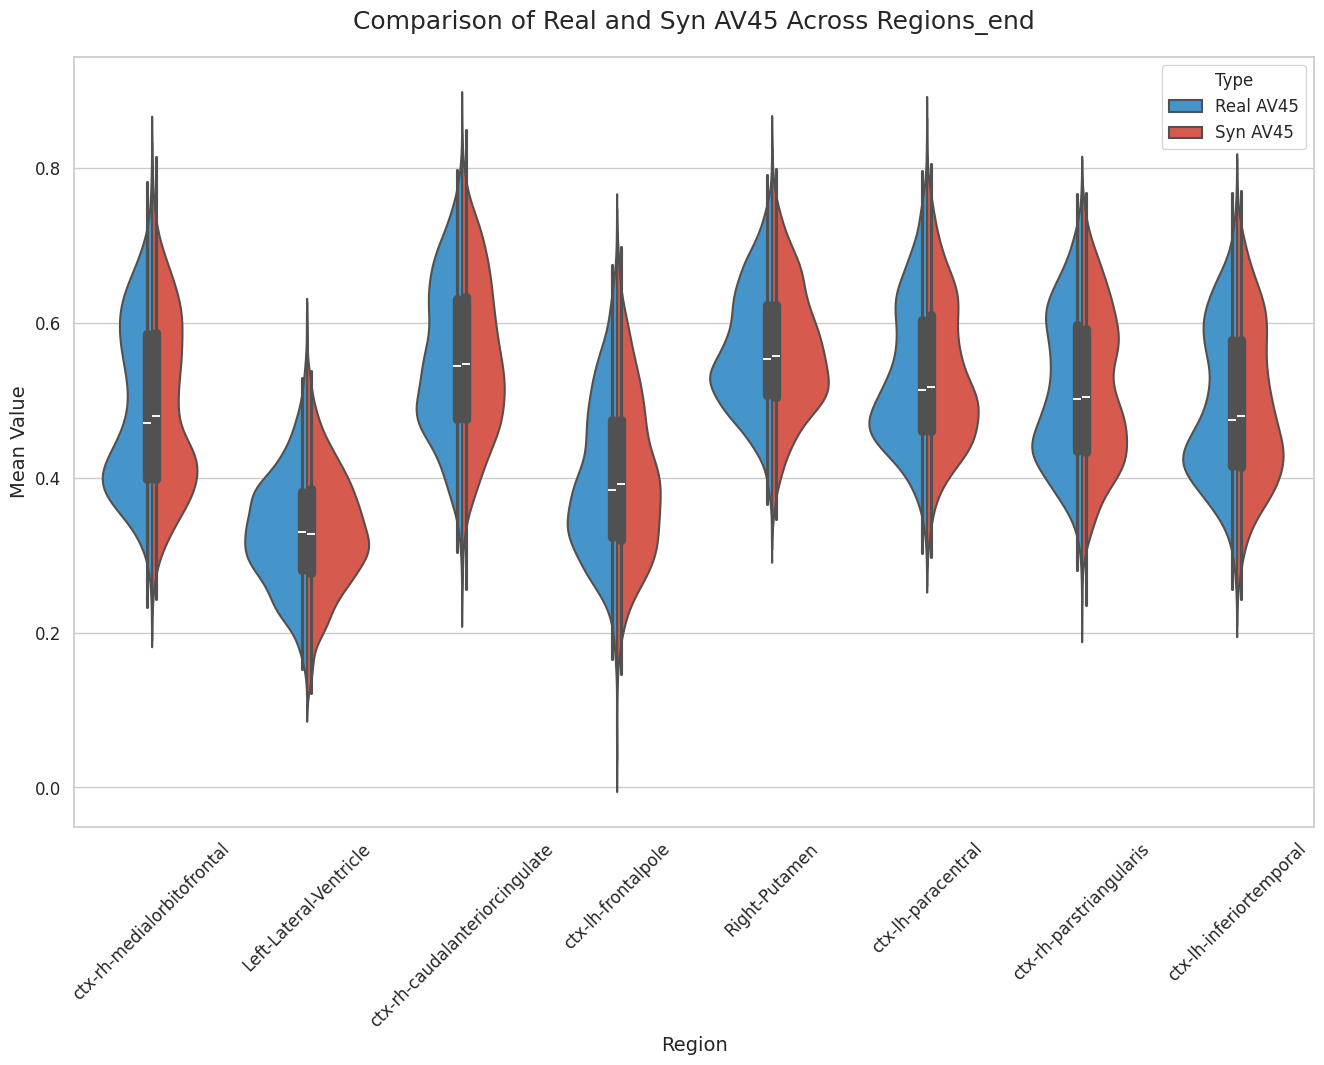

In [34]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind

# 定义路径
output_dir = "/home/ssddata/liutuo/liutuo_data/statistics_of_regions_av45"

# 加载 CSV 文件
def load_csv(file_path):
    return pd.read_csv(file_path)

# 统计检验和绘图
def analyze_and_plot():
    # 获取目录中的所有 CSV 文件
    csv_files = [f for f in os.listdir(output_dir) if f.endswith(".csv")]
    
    # 如果没有 CSV 文件，直接退出
    if not csv_files:
        print("No CSV files found in the directory.")
        return

    # 只取前 12 个 CSV 文件
    csv_files = csv_files[86:]
    print(f"Analyzing the first 12 CSV files: {csv_files}")

    # 创建一个 DataFrame 存储所有数据
    all_data = []

    # 用于保存显著性信息
    significance_info = {}

    for csv_file in csv_files:
        csv_path = os.path.join(output_dir, csv_file)
        if not os.path.exists(csv_path):
            print(f"File not found: {csv_path}")
            continue

        # 提取区域名称（去掉 "region_" 和 ".csv"）
        region = os.path.splitext(csv_file)[0].replace("region_", "")

        csv_data = load_csv(csv_path)
        real_av45 = csv_data["real_av45_mean"].values
        syn_av45 = csv_data["syn_av45_mean"].values

        # 独立样本 t 检验
        t_stat, p_value = ttest_ind(real_av45, syn_av45)
        print(f"Region {region}:")
        print(f"  T-statistic: {t_stat:.4f}, P-value: {p_value:.4f}")
        if p_value < 0.05:
            print("  Significant difference detected!")
            significance_info[region] = "Significant"
        else:
            print("  No significant difference.")
            significance_info[region] = "Not Significant"

        # 合并数据为长格式
        data = pd.DataFrame({
            "Real AV45": real_av45,
            "Syn AV45": syn_av45
        }).melt(var_name="Type", value_name="Mean Value")

        # 添加区域标签
        data["Region"] = region

        # 将数据追加到总数据集
        all_data.append(data)

    # 合并所有数据
    combined_data = pd.concat(all_data, ignore_index=True)

    # 设置 Seaborn 主题和颜色
    sns.set_theme(style="whitegrid")
    # 自定义颜色方案
    palette = {"Real AV45": "#3498DB", "Syn AV45": "#E74C3C"}  # 蓝色和红色

    # 绘制小提琴图 + 箱线图
    plt.figure(figsize=(16, 10))
    ax = sns.violinplot(
        data=combined_data,
        x="Region",
        y="Mean Value",
        hue="Type",
        inner="box",
        split=True,
        palette=palette,
        linewidth=1.5,
        saturation=0.8
    )

    # 添加显著性标注
    y_max = combined_data["Mean Value"].max() * 1.1  # 动态计算 y 轴最大值
    for i, region in enumerate(significance_info.keys()):
        if significance_info[region] == "Significant":
            plt.text(i, y_max, "*", ha="center", fontsize=16, color="red", fontweight="bold")

    # 在第一个箱型图上添加红星
    # 获取第一个箱型图的最大值
    # first_region_data = combined_data[combined_data["Region"] == combined_data["Region"].unique()[10]]
    # first_region_max = first_region_data["Mean Value"].max()
    # # 添加红星
    # plt.text(10, first_region_max + 0.1, "*", ha="center", fontsize=24, color="red", fontweight="bold")

    # 图形细节优化
    plt.title("Comparison of Real and Syn AV45 Across Regions_end", fontsize=18, pad=20)
    plt.ylabel("Mean Value", fontsize=14)
    plt.xlabel("Region", fontsize=14)
    plt.xticks(fontsize=12, rotation=45)  # 旋转 x 轴标签以便更好显示
    plt.yticks(fontsize=12)
    plt.legend(title="Type", title_fontsize=12, fontsize=12, loc="upper right", frameon=True)

    # 保存图像
    plot_path = os.path.join(output_dir, "regions_comparison_violin_first_end.png")
    plt.savefig(plot_path, dpi=300, bbox_inches="tight")
    print(f"Saved plot to {plot_path}")

    # 显示图像
    plt.show()

# 主逻辑
analyze_and_plot()

In [7]:
import pandas as pd

# Read the CSV file
file_path = '/home/ssddata/liutuo/liutuo_data/statistics_of_regions_fdg_new/region_7.0 and8.csv'
df = pd.read_csv(file_path)

# Calculate the mean of the two columns for each subject
df['syn_fdg_mean_7and8'] = df[['syn_fdg_mean_7', 'syn_fdg_mean_8']].mean(axis=1)

# Save the updated dataframe back to CSV (optional)
df.to_csv(file_path, index=False)

# Display the result
print(df.head())

      subject  real_fdg_mean_7  syn_fdg_mean_7  real_fdg_mean_8  \
0  002_S_0295         0.552364        0.564609         0.613748   
1  002_S_0413         0.441491        0.460625         0.490405   
2  002_S_0685         0.507292        0.520839         0.543297   
3  002_S_0729         0.492558        0.495870         0.531312   
4  002_S_1155         0.506458        0.509696         0.569615   

   syn_fdg_mean_8  real_fdg_mean_7and8  syn_fdg_mean_7and8  
0        0.615992             0.583056            0.590301  
1        0.506648             0.465948            0.483637  
2        0.557637             0.525295            0.539238  
3        0.544992             0.511935            0.520431  
4        0.559558             0.538036            0.534627  
